# 4. Pareto Frontier and QoS Sensitivity Analysis

Analyze the saved optimized-allocation candidate pairs from notebook 02.
The experiment uses one antenna at the BS and one at each AMR: each link is
SISO, with no MIMO spatial-multiplexing gain. This notebook changes neither
the antenna model nor the channel fingerprint.


Each candidate pair has a mission time `T` and minimum sampled bottleneck
rate `R_min`. We minimize time while requiring `R_min >= R_QoS`.

The Pareto frontier and QoS ceiling apply only to the saved candidate set,
static channel model, and evaluation times. They are not global bounds over
all possible paths or all single-antenna systems. A failed shortest-route
baseline does not imply that every communication-aware route must fail.


## 0. Imports and QoS Configuration


In [1]:
import importlib

import matplotlib.pyplot as plt
import numpy as np

import project_config

importlib.reload(project_config)

from project_config import (
    FIGURES_DIR, PATH_PLANNING_RESULTS_PATH,
)

## Input: Load and Validate the Saved Planning Results


In [2]:
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
if not PATH_PLANNING_RESULTS_PATH.exists():
    raise FileNotFoundError("Run notebook 02 first to generate path_planning_results.npz.")

required_keys = (
    "pair_summaries", "amr1_candidate_lengths", "amr2_candidate_lengths",
    "r_qos_required_bps", "joint_mission_time_s", "joint_r_min_bps",
)
with np.load(PATH_PLANNING_RESULTS_PATH, allow_pickle=False) as data:
    missing = [key for key in required_keys if key not in data.files]
    if missing:
        raise KeyError(f"Rerun notebook 02. Missing saved keys: {missing}")
    PAIR_SUMMARIES = data["pair_summaries"]
    AMR1_LENGTHS = data["amr1_candidate_lengths"]
    AMR2_LENGTHS = data["amr2_candidate_lengths"]
    # Use the target from the saved experiment, even if project_config was edited.
    R_QOS_REQUIRED_MBPS = float(data["r_qos_required_bps"].item()) / 1e6
    SAVED_JOINT_T = float(data["joint_mission_time_s"].item())
    SAVED_JOINT_RMIN = float(data["joint_r_min_bps"].item()) / 1e6


def validate_pair_data(pairs, lengths1, lengths2):
    if pairs.ndim != 2 or pairs.shape[1] != 4 or len(pairs) == 0:
        raise ValueError("pair_summaries must be a nonempty array with columns [i, j, T, R_min].")
    if not np.all(np.isfinite(pairs)) or np.any(pairs < 0):
        raise ValueError("Pair indices, times, and rates must be finite and nonnegative.")
    for lengths in (lengths1, lengths2):
        if lengths.ndim != 1 or len(lengths) == 0:
            raise ValueError("Candidate lengths must be nonempty one-dimensional arrays.")
        if not np.all(np.isfinite(lengths)) or np.any(lengths < 0):
            raise ValueError("Candidate lengths must be finite and nonnegative.")
    ids = pairs[:, :2]
    if np.any(ids != np.floor(ids)):
        raise ValueError("Candidate indices must be integers.")
    if np.any(ids[:, 0] >= len(lengths1)) or np.any(ids[:, 1] >= len(lengths2)):
        raise ValueError("Candidate index exceeds the saved length-array bounds.")
    if len(np.unique(ids, axis=0)) != len(pairs):
        raise ValueError("Duplicate candidate-pair indices in the saved results.")
    if len(pairs) != len(lengths1) * len(lengths2):
        raise ValueError("Saved results do not cover all candidate-pair combinations.")


validate_pair_data(PAIR_SUMMARIES, AMR1_LENGTHS, AMR2_LENGTHS)
if not np.isfinite(R_QOS_REQUIRED_MBPS) or R_QOS_REQUIRED_MBPS <= 0:
    raise ValueError("The saved QoS target must be finite and positive.")
PAIR_I = PAIR_SUMMARIES[:, 0].astype(int)
PAIR_J = PAIR_SUMMARIES[:, 1].astype(int)
PAIR_T = PAIR_SUMMARIES[:, 2]
PAIR_RMIN = PAIR_SUMMARIES[:, 3] / 1e6
PAIR_L1 = AMR1_LENGTHS[PAIR_I]
PAIR_L2 = AMR2_LENGTHS[PAIR_J]

print(f"Number of route pairs: {len(PAIR_SUMMARIES)}")
print(f"Saved QoS target: {R_QOS_REQUIRED_MBPS:g} Mbps")
print(f"T range: {PAIR_T.min():.2f} ~ {PAIR_T.max():.2f} s")
print(f"Minimum sampled rate range: {PAIR_RMIN.min():.2f} ~ {PAIR_RMIN.max():.2f} Mbps")


Number of route pairs: 900
Saved QoS target: 30 Mbps
T range: 36.97 ~ 54.04 s
Minimum sampled rate range: 1.84 ~ 35.93 Mbps


## 1. Selection Rule and Candidate-Set Pareto Frontier

A point dominates another when its time is no greater and its rate is no
lower, with at least one strict improvement. Equal `(T, R_min)` points have
one representative on the plotted frontier. Prefer points toward the upper
left: smaller time and higher minimum sampled rate.

Feasibility means `R_min >= R_QoS`, using the target saved by notebook 02
(30 Mbps in the current experiment). Among feasible pairs, minimize time and
break ties by higher rate. If none qualifies, report an infeasible fallback
with the highest rate, breaking ties by lower time. The frontier is for the
finite evaluated candidate set, not all possible routes.


In [3]:
# =========================================================
# Prefer route pairs with lower T and higher R_min.
# =========================================================
def pareto_frontier(pair_t, pair_rmin):
    pair_t = np.asarray(pair_t, dtype=float)
    pair_rmin = np.asarray(pair_rmin, dtype=float)
    if pair_t.ndim != 1 or pair_t.shape != pair_rmin.shape or not len(pair_t):
        raise ValueError("Times and rates must be equally sized nonempty vectors.")
    if not np.all(np.isfinite(pair_t)) or not np.all(np.isfinite(pair_rmin)):
        raise ValueError("Pareto times and rates must be finite.")

    rows = np.arange(len(pair_t))

    # Sort by increasing T, then decreasing R_min for ties.
    order = np.lexsort((-pair_rmin, pair_t))
    ordered_rows = rows[order]

    frontier_rows = []
    best_rmin = -np.inf

    # Examine route pairs from the smallest T upward.
    # Add a point only when its R_min exceeds every earlier value.
    for row in ordered_rows:
        if pair_rmin[row] > best_rmin:
            frontier_rows.append(row)
            best_rmin = pair_rmin[row]

    return np.asarray(frontier_rows, dtype=int)


# =========================================================
# Select one route pair for a specified QoS target using the following rule:
# - If feasible pairs exist: minimize T.
# - If all pairs are infeasible: maximize R_min.
# =========================================================
def select_pair(r_qos_mbps):
    if not np.isfinite(r_qos_mbps) or r_qos_mbps < 0:
        raise ValueError("QoS must be a finite nonnegative rate in Mbps.")
    feasible_rows = np.flatnonzero(PAIR_RMIN >= r_qos_mbps)

    if feasible_rows.size:
        # Among feasible pairs, minimize T and then maximize R_min.
        order = np.lexsort(
            (-PAIR_RMIN[feasible_rows], PAIR_T[feasible_rows])
        )
        return int(feasible_rows[order[0]]), True

    # If all pairs are infeasible, maximize R_min and then minimize T.
    order = np.lexsort((PAIR_T, -PAIR_RMIN))
    return int(order[0]), False


# Identify the row indices on the Pareto frontier.
FRONTIER_ROWS = pareto_frontier(PAIR_T, PAIR_RMIN)
FRONTIER_T = PAIR_T[FRONTIER_ROWS]
FRONTIER_RMIN = PAIR_RMIN[FRONTIER_ROWS]

# Select the JOINT result using the QoS target.
JOINT_ROW, JOINT_FEASIBLE = select_pair(R_QOS_REQUIRED_MBPS)
JOINT_T = PAIR_T[JOINT_ROW]
JOINT_RMIN = PAIR_RMIN[JOINT_ROW]

if not (
    np.isclose(JOINT_T, SAVED_JOINT_T, rtol=1e-9)
    and np.isclose(JOINT_RMIN, SAVED_JOINT_RMIN, rtol=1e-9)
):
    raise ValueError("Selected pair disagrees with the saved JOINT result; rerun notebook 02.")

# Build a feasibility mask for color-coding `11_pareto.png`.
FEASIBLE_MASK = PAIR_RMIN >= R_QOS_REQUIRED_MBPS


# =========================================================
# Summarize the selected result
# =========================================================
print(f"Candidate-set Pareto frontier: {len(FRONTIER_ROWS)} points")
print(
    f"Task 2 JOINT: AMR1 #{PAIR_I[JOINT_ROW] + 1}, "
    f"AMR2 #{PAIR_J[JOINT_ROW] + 1}, "
    f"T = {JOINT_T:.2f} s, R_min = {JOINT_RMIN:.2f} Mbps"
)
print(
    f"Meets the {R_QOS_REQUIRED_MBPS:.0f} Mbps QoS target: "
    f"{JOINT_FEASIBLE}"
)


Candidate-set Pareto frontier: 4 points
Task 2 JOINT: AMR1 #5, AMR2 #2, T = 40.38 s, R_min = 33.53 Mbps
Meets the 30 Mbps QoS target: True


## 2. T4.1 Generate `11_pareto.png`


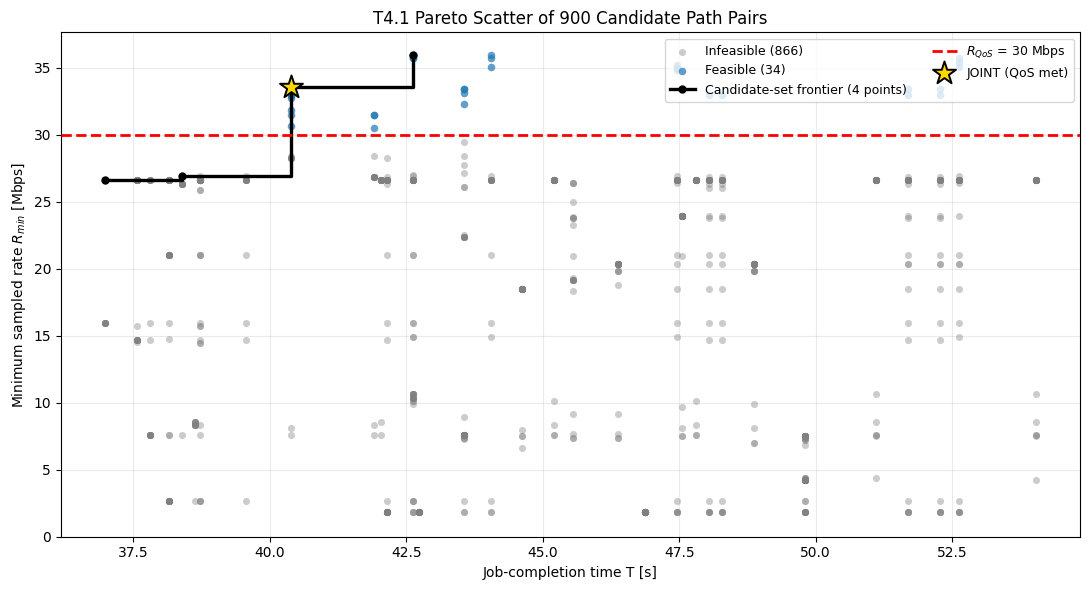

In [4]:
n_feasible = int(FEASIBLE_MASK.sum())         # Count feasible pairs
n_infeasible = int((~FEASIBLE_MASK).sum())    # Count infeasible pairs

fig, ax = plt.subplots(figsize=(11, 6))       # Create the figure

# Infeasible route pairs (gray)
ax.scatter(
    PAIR_T[~FEASIBLE_MASK],
    PAIR_RMIN[~FEASIBLE_MASK],
    color="gray",
    alpha=0.4,
    s=26,
    linewidths=0,
    label=f"Infeasible ({n_infeasible})",
    zorder=2,
)

# Feasible route pairs (blue)
ax.scatter(
    PAIR_T[FEASIBLE_MASK],
    PAIR_RMIN[FEASIBLE_MASK],
    color="tab:blue",
    alpha=0.7,
    s=30,
    linewidths=0,
    label=f"Feasible ({n_feasible})",
    zorder=3,
)

# Draw representative non-dominated points; step connectors are visual guides.
ax.plot(
    FRONTIER_T,
    FRONTIER_RMIN,
    color="black",
    linewidth=2.4,
    drawstyle="steps-post",
    marker="o", markersize=5,
    label=f"Candidate-set frontier ({len(FRONTIER_ROWS)} points)",
    zorder=4,
)

# Draw the QoS target as a red horizontal reference line.
ax.axhline(
    R_QOS_REQUIRED_MBPS,
    color="red",
    linestyle="--",
    linewidth=2.0,
    label=rf"$R_{{QoS}}$ = {R_QOS_REQUIRED_MBPS:.0f} Mbps",
    zorder=5,
)

# Highlight the selected JOINT route pair with a gold star.
ax.scatter(
    JOINT_T,
    JOINT_RMIN,
    marker="*",
    s=300,
    color="gold",
    edgecolors="black",
    linewidths=1.4,
    label="JOINT (QoS met)" if JOINT_FEASIBLE else "JOINT fallback (QoS unmet)",
    zorder=6,
)

# Configure axis labels and title.
ax.set(
    xlabel="Job-completion time T [s]",
    ylabel=r"Minimum sampled rate $R_{min}$ [Mbps]",
    title=f"T4.1 Pareto Scatter of {len(PAIR_SUMMARIES)} Candidate Path Pairs",
)

# Configure axis limits.
ax.set_xlim(PAIR_T.min() - 0.8, PAIR_T.max() + 0.8)
ax.set_ylim(bottom=0)
ax.grid(alpha=0.25)              # Grid
ax.legend(ncol=2, fontsize=9)    # Legend

fig.tight_layout()

# Save the figure
PARETO_PATH = FIGURES_DIR / "11_pareto.png"
fig.savefig(PARETO_PATH, dpi=300, bbox_inches="tight")
plt.show()


## 3. T4.1 Diagnostic Values for the Written Questions


In [5]:
# Compare objective values, because duplicate points may use another representative.
joint_on_frontier = bool(np.any(
    (FRONTIER_T == JOINT_T) & (FRONTIER_RMIN == JOINT_RMIN)
))
print("\n[Q2] JOINT and the candidate-set Pareto frontier")
print(f"  JOINT objective point is on the frontier: {joint_on_frontier}")
if JOINT_FEASIBLE:
    print("  Selection: minimum time among QoS-feasible pairs, then highest rate.")
else:
    print("  No feasible pair: maximum-rate fallback, then minimum time. QoS is unmet.")

print("\n[Q3] Frontier structure")
print(f"  Distinct T values (rounded for display): {len(np.unique(np.round(PAIR_T, 6)))}")
print(f"  Distinct non-dominated objective points: {len(FRONTIER_ROWS)}")
print("  The frontier is a finite set; connecting steps are visual guides.")
print("\n Pareto frontier")
print("     T [s]   R_min [Mbps]   pair")
for row in FRONTIER_ROWS:
    print(f"    {PAIR_T[row]:6.2f}   {PAIR_RMIN[row]:12.2f}   "
          f"(#{PAIR_I[row] + 1}, #{PAIR_J[row] + 1})")



[Q2] JOINT and the candidate-set Pareto frontier
  JOINT objective point is on the frontier: True
  Selection: minimum time among QoS-feasible pairs, then highest rate.

[Q3] Frontier structure
  Distinct T values (rounded for display): 33
  Distinct non-dominated objective points: 4
  The frontier is a finite set; connecting steps are visual guides.

 Pareto frontier
     T [s]   R_min [Mbps]   pair
     36.97          26.61   (#1, #23)
     38.38          26.91   (#2, #22)
     40.38          33.53   (#5, #2)
     42.63          35.93   (#13, #2)


## 4. QoS Target Sweep

Reuse the same saved rates and candidate routes while changing only the
required rate. This does not regenerate routes, change antenna count, or
rerun ray tracing. The minimum feasible time is constant between frontier
rate thresholds. Equality at a threshold remains feasible for the preceding
shorter-time solution. An infeasible fallback is not a QoS-satisfying result.


In [6]:
# QoS targets included in the sweep
R_QOS_SWEEP_MBPS = np.array(
    [5, 10, 15, 20, 25, 27, 30, 33, 35, 36, 40],
    dtype=float,
)

R_QOS_SWEEP_MBPS = np.unique(np.append(R_QOS_SWEEP_MBPS, R_QOS_REQUIRED_MBPS))

# Allocate arrays for sweep results.
SWEEP_ROWS = np.empty(len(R_QOS_SWEEP_MBPS), dtype=int)
SWEEP_FEASIBLE = np.empty(len(R_QOS_SWEEP_MBPS), dtype=bool)
SWEEP_COUNTS = np.empty(len(R_QOS_SWEEP_MBPS), dtype=int)

# Select a route pair for each QoS target.
for n, r_qos in enumerate(R_QOS_SWEEP_MBPS):
    SWEEP_ROWS[n], SWEEP_FEASIBLE[n] = select_pair(r_qos)   # Evaluate the current QoS target.
    SWEEP_COUNTS[n] = int((PAIR_RMIN >= r_qos).sum())       # Count saved pairs meeting the current target.

# Extract results for the selected route pairs.
SWEEP_T = PAIR_T[SWEEP_ROWS]
SWEEP_RMIN = PAIR_RMIN[SWEEP_ROWS]
SWEEP_L1 = PAIR_L1[SWEEP_ROWS]
SWEEP_L2 = PAIR_L2[SWEEP_ROWS]

# Find the shortest mission-completion time across the saved candidate set.
MIN_T = float(PAIR_T.min())

# Among minimum-time pairs, find the largest R_min.
EASY_MAX_MBPS = float(PAIR_RMIN[PAIR_T == MIN_T].max())

# Find the largest R_min achievable across the saved candidate set.
MAX_ACHIEVABLE_MBPS = float(PAIR_RMIN.max())

print("R_QoS   feasible      T      R_min      L1      L2      pair")   # Column headers
print(f"[Mbps]    /{len(PAIR_SUMMARIES)}       [s]    [Mbps]     [m]     [m]")             # Units

for n, r_qos in enumerate(R_QOS_SWEEP_MBPS):
    row = SWEEP_ROWS[n]
    status = "OK" if SWEEP_FEASIBLE[n] else "FALLBACK"
    print(
        f"{r_qos:5.0f}   {SWEEP_COUNTS[n]:6d}   {SWEEP_T[n]:7.2f}   "
        f"{SWEEP_RMIN[n]:7.2f}   {SWEEP_L1[n]:6.2f}   "
        f"{SWEEP_L2[n]:6.2f}   "
        f"(#{PAIR_I[row] + 1:2d}, #{PAIR_J[row] + 1:2d})   {status}"
    )

# Fallback: no route pair meets QoS, so select the pair with the largest R_min.

R_QoS   feasible      T      R_min      L1      L2      pair
[Mbps]    /900       [s]    [Mbps]     [m]     [m]
    5      725     36.97     26.61    18.49    18.49   (# 1, #23)   OK
   10      618     36.97     26.61    18.49    18.49   (# 1, #23)   OK
   15      576     36.97     26.61    18.49    18.49   (# 1, #23)   OK
   20      512     36.97     26.61    18.49    18.49   (# 1, #23)   OK
   25      406     36.97     26.61    18.49    18.49   (# 1, #23)   OK
   27       46     40.38     33.53    19.36    20.19   (# 5, # 2)   OK
   30       34     40.38     33.53    19.36    20.19   (# 5, # 2)   OK
   33       19     40.38     33.53    19.36    20.19   (# 5, # 2)   OK
   35       11     42.63     35.93    21.31    20.19   (#13, # 2)   OK
   36        0     42.63     35.93    21.31    20.19   (#13, # 2)   FALLBACK
   40        0     42.63     35.93    21.31    20.19   (#13, # 2)   FALLBACK


## 5. T4.2 Generate `12_qos_sweep.png`


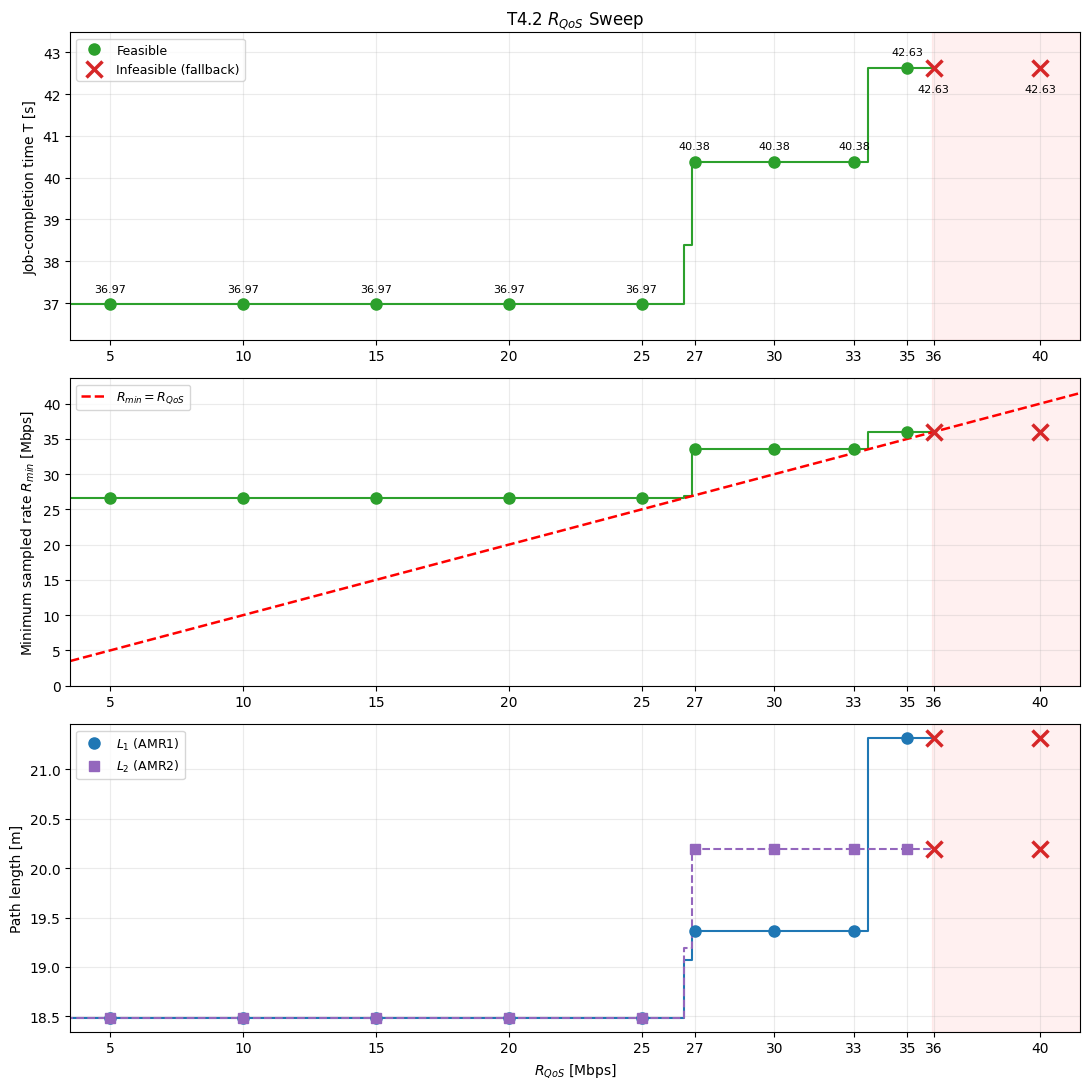

In [7]:
# Connect only feasible points; leave gaps across infeasible regions.
def feasible_values(values):
    return np.where(SWEEP_FEASIBLE, values, np.nan)

# For each interval (previous frontier rate, current frontier rate], the
# current frontier pair minimizes feasible time. Steps change after equality.
STEP_QOS = np.r_[0.0, FRONTIER_RMIN]
STEP_T = np.r_[FRONTIER_T[0], FRONTIER_T]
STEP_RMIN = np.r_[FRONTIER_RMIN[0], FRONTIER_RMIN]
STEP_L1 = np.r_[PAIR_L1[FRONTIER_ROWS[0]], PAIR_L1[FRONTIER_ROWS]]
STEP_L2 = np.r_[PAIR_L2[FRONTIER_ROWS[0]], PAIR_L2[FRONTIER_ROWS]]

# Set the x-axis range.
x_min = R_QOS_SWEEP_MBPS.min() - 1.5
x_max = R_QOS_SWEEP_MBPS.max() + 1.5

# Create three vertically stacked plots.
fig, axes = plt.subplots(3, 1, figsize=(11, 11), sharex=True)
ax_t, ax_r, ax_l = axes


# Exact candidate-selection intervals (no feasible segment beyond the maximum rate).
ax_t.step(STEP_QOS, STEP_T, where="pre", color="tab:green", linewidth=1.5)
ax_r.step(STEP_QOS, STEP_RMIN, where="pre", color="tab:green", linewidth=1.5)
ax_l.step(STEP_QOS, STEP_L1, where="pre", color="tab:blue", linewidth=1.5)
ax_l.step(STEP_QOS, STEP_L2, where="pre", color="tab:purple", linestyle="--", linewidth=1.5)

# (1) Mission-completion time T
ax_t.plot(
    R_QOS_SWEEP_MBPS,
    feasible_values(SWEEP_T),
    "o",
    color="tab:green",
    linewidth=2.0,
    markersize=8,
    label="Feasible",
)
ax_t.plot(
    R_QOS_SWEEP_MBPS[~SWEEP_FEASIBLE],
    SWEEP_T[~SWEEP_FEASIBLE],
    "x",
    color="tab:red",
    markersize=11,
    markeredgewidth=2.5,
    label="Infeasible (fallback)",
)
for r_qos, t_value, feasible in zip(
    R_QOS_SWEEP_MBPS, SWEEP_T, SWEEP_FEASIBLE
):
    ax_t.annotate(
        f"{t_value:.2f}",
        xy=(r_qos, t_value),
        xytext=(0, 9 if feasible else -17),
        textcoords="offset points",
        ha="center",
        fontsize=8,
    )
ax_t.set(
    ylabel="Job-completion time T [s]",
    title=r"T4.2 $R_{QoS}$ Sweep",
)
ax_t.margins(y=0.15)  # Leave room for the value labels above the highest points.
ax_t.legend(fontsize=9)


# (2) Achieved R_min
ax_r.plot(
    [x_min, x_max],
    [x_min, x_max],
    "--",
    color="red",
    linewidth=1.8,
    label=r"$R_{min}=R_{QoS}$",
)
ax_r.plot(
    R_QOS_SWEEP_MBPS,
    feasible_values(SWEEP_RMIN),
    "o",
    color="tab:green",
    linewidth=2.0,
    markersize=8,
)
ax_r.plot(
    R_QOS_SWEEP_MBPS[~SWEEP_FEASIBLE],
    SWEEP_RMIN[~SWEEP_FEASIBLE],
    "x",
    color="tab:red",
    markersize=11,
    markeredgewidth=2.5,
)
ax_r.set(ylabel=r"Minimum sampled rate $R_{min}$ [Mbps]",
         ylim=(0, max(x_max, MAX_ACHIEVABLE_MBPS) * 1.05))
ax_r.legend(fontsize=9)


# (3) Route lengths selected for the two AMRs
ax_l.plot(
    R_QOS_SWEEP_MBPS,
    feasible_values(SWEEP_L1),
    "o",
    color="tab:blue",
    linewidth=2.0,
    markersize=8,
    label=r"$L_1$ (AMR1)",
)
ax_l.plot(
    R_QOS_SWEEP_MBPS,
    feasible_values(SWEEP_L2),
    "s",
    color="tab:purple",
    linewidth=2.0,
    markersize=7,
    label=r"$L_2$ (AMR2)",
)
ax_l.plot(
    R_QOS_SWEEP_MBPS[~SWEEP_FEASIBLE],
    SWEEP_L1[~SWEEP_FEASIBLE],
    "x",
    color="tab:red",
    markersize=11,
    markeredgewidth=2.5,
)
ax_l.plot(
    R_QOS_SWEEP_MBPS[~SWEEP_FEASIBLE],
    SWEEP_L2[~SWEEP_FEASIBLE],
    "x",
    color="tab:red",
    markersize=11,
    markeredgewidth=2.5,
)
ax_l.set(
    xlabel=r"$R_{QoS}$ [Mbps]",
    ylabel="Path length [m]",
    xlim=(x_min, x_max),
)


# Apply shared formatting to all plots.
for ax in axes:
    ax.set_xticks(R_QOS_SWEEP_MBPS)
    if MAX_ACHIEVABLE_MBPS < x_max:
        ax.axvspan(max(x_min, MAX_ACHIEVABLE_MBPS), x_max, color="red", alpha=0.06)
    ax.tick_params(axis="x", labelbottom=True)
    ax.grid(alpha=0.25)
ax_l.legend(fontsize=9)
for ax in axes:
    ax.grid(alpha=0.25)
fig.tight_layout()


# Save the figure
QOS_SWEEP_PATH = FIGURES_DIR / "12_qos_sweep.png"
fig.savefig(QOS_SWEEP_PATH, dpi=300, bbox_inches="tight")
plt.show()


## 6. T4.2 Written-Question Diagnostics


In [8]:
print("[Q1] Operating regimes within the saved candidate set")
print(f"  Minimum-time regime: R_QoS <= {EASY_MAX_MBPS:.2f} Mbps, T = {MIN_T:.2f} s")
if MAX_ACHIEVABLE_MBPS > EASY_MAX_MBPS:
    print(f"  Longer-time regime: {EASY_MAX_MBPS:.2f} < R_QoS <= {MAX_ACHIEVABLE_MBPS:.2f} Mbps")
print(f"  No feasible saved pair: R_QoS > {MAX_ACHIEVABLE_MBPS:.2f} Mbps")
print("  Printed thresholds are rounded; selection uses full precision.")

print("\n  Minimum feasible T(R_QoS) intervals")
previous_rmin = 0.0
for index, row in enumerate(FRONTIER_ROWS):
    left_bracket = "[" if index == 0 else "("
    print(f"  {left_bracket}{previous_rmin:.6f}, {PAIR_RMIN[row]:.6f}] Mbps "
          f"-> T = {PAIR_T[row]:.2f} s, "
          f"pair (#{PAIR_I[row] + 1}, #{PAIR_J[row] + 1})")
    previous_rmin = PAIR_RMIN[row]
print(f"  ({previous_rmin:.6f}, inf) Mbps -> infeasible")

print("\n[Q2] Which AMR first uses a route longer than its shortest candidate?")
FIRST_DETOUR_THRESHOLDS = []
for amr, lengths, pair_lengths in (
    (1, AMR1_LENGTHS, PAIR_L1), (2, AMR2_LENGTHS, PAIR_L2),
):
    detours = np.flatnonzero(pair_lengths[FRONTIER_ROWS] > lengths.min() + 1e-8)
    if not detours.size:
        FIRST_DETOUR_THRESHOLDS.append(None)
        print(f"  AMR{amr}: no longer route on the selected frontier.")
        continue
    index = int(detours[0])
    threshold = 0.0 if index == 0 else float(FRONTIER_RMIN[index - 1])
    FIRST_DETOUR_THRESHOLDS.append(threshold)
    condition = "at the lowest target" if index == 0 else f"above {threshold:.6f} Mbps"
    print(f"  AMR{amr}: first longer route {condition}.")
if all(value is not None for value in FIRST_DETOUR_THRESHOLDS):
    first1, first2 = FIRST_DETOUR_THRESHOLDS
    if first1 == first2:
        print("  Both first use longer routes at the same QoS transition.")
    else:
        print(f"  AMR{1 if first1 < first2 else 2} first uses a longer route.")

print("\n[Q3] Minimum completion time for the saved QoS target")
if JOINT_FEASIBLE:
    print(f"  At {R_QOS_REQUIRED_MBPS:g} Mbps: minimum feasible T = {JOINT_T:.2f} s.")
else:
    print(f"  At {R_QOS_REQUIRED_MBPS:g} Mbps: no feasible candidate pair.")
    print(f"  Fallback T = {JOINT_T:.2f} s, rate = {JOINT_RMIN:.2f} Mbps; QoS is unmet.")
print(f"  For comparison, ignoring QoS gives a minimum T of {MIN_T:.2f} s.")


[Q1] Operating regimes within the saved candidate set
  Minimum-time regime: R_QoS <= 26.61 Mbps, T = 36.97 s
  Longer-time regime: 26.61 < R_QoS <= 35.93 Mbps
  No feasible saved pair: R_QoS > 35.93 Mbps
  Printed thresholds are rounded; selection uses full precision.

  Minimum feasible T(R_QoS) intervals
  [0.000000, 26.608886] Mbps -> T = 36.97 s, pair (#1, #23)
  (26.608886, 26.911172] Mbps -> T = 38.38 s, pair (#2, #22)
  (26.911172, 33.525309] Mbps -> T = 40.38 s, pair (#5, #2)
  (33.525309, 35.932358] Mbps -> T = 42.63 s, pair (#13, #2)
  (35.932358, inf) Mbps -> infeasible

[Q2] Which AMR first uses a route longer than its shortest candidate?
  AMR1: first longer route above 26.608886 Mbps.
  AMR2: first longer route above 26.608886 Mbps.
  Both first use longer routes at the same QoS transition.

[Q3] Minimum completion time for the saved QoS target
  At 30 Mbps: minimum feasible T = 40.38 s.
  For comparison, ignoring QoS gives a minimum T of 36.97 s.
